# 📈 Lekcja 2: Oczami modelu — logarytmowanie cen i odkrywanie zależności

Gratulacje za ukończenie Lekcji 1! Wiemy już, że w naszych danych o cenach domów (`SalePrice`) większość nieruchomości kosztuje około 130 000 – 200 000 \$, ale mamy też kilku „miliarderów w barze” (rezydencje po 500 000 – 755 000 \$), którzy mocno przeciągają wykres w prawą stronę.

W tej lekcji zrobimy dwie bardzo ważne rzeczy:
1. **Naprawimy skośny wykres cen za pomocą logarytmu (`np.log1p`)** i zobaczymy na dwóch wykresach obok siebie, jak zmienia się kształt danych.
2. **Poszukamy odpowiedzi na pytanie: „Co najbardziej podbija cenę domu?”**, rysując wykres punktowy dla metrażu (`GrLivArea`) oraz wykres pudełkowy dla jakości wykonania (`OverallQual`).

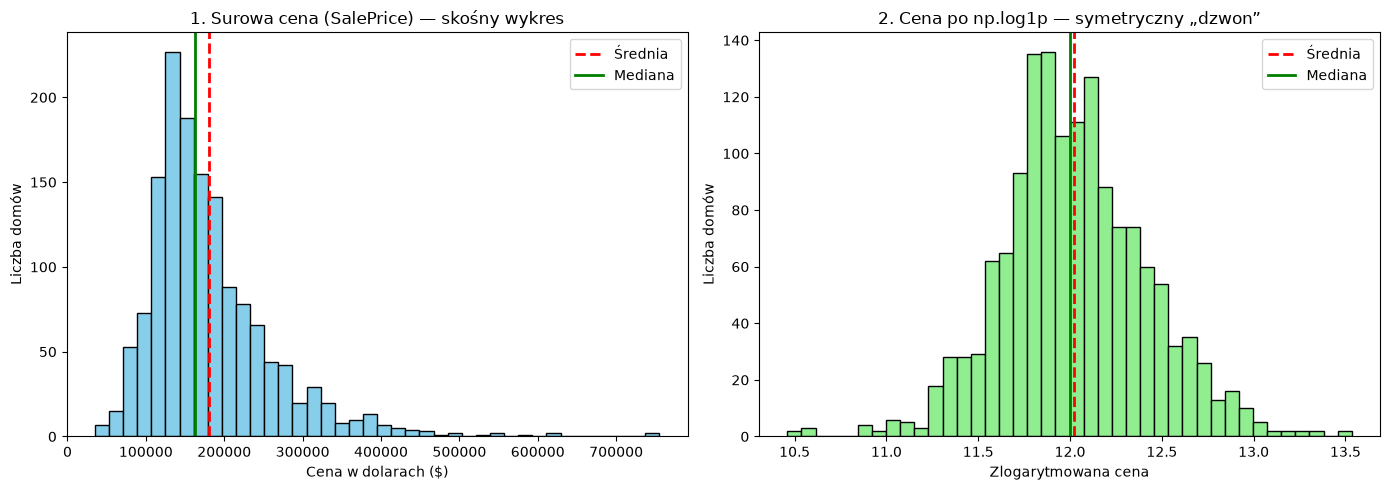

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Wczytujemy zbiór treningowy z folderu ../data/
train = pd.read_csv('../data/train.csv')

# Tworzymy nową kolumnę z ceną po zlogarytmowaniu
train['SalePrice_Log'] = np.log1p(train['SalePrice'])

# Przygotowujemy płótno na DWA wykresy obok siebie (1 wiersz, 2 kolumny)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# WYKRES LEWY (ax1): Surowa cena w dolarach
ax1.hist(train['SalePrice'], bins=40, color='skyblue', edgecolor='black')
ax1.axvline(train['SalePrice'].mean(), color='red', linestyle='--', linewidth=2, label='Średnia')
ax1.axvline(train['SalePrice'].median(), color='green', linestyle='-', linewidth=2, label='Mediana')
ax1.set_title('1. Surowa cena (SalePrice) — skośny wykres')
ax1.set_xlabel('Cena w dolarach ($)')
ax1.set_ylabel('Liczba domów')
ax1.legend()

# WYKRES PRAWY (ax2): Cena po zlogarytmowaniu (np.log1p)
ax2.hist(train['SalePrice_Log'], bins=40, color='lightgreen', edgecolor='black')
ax2.axvline(train['SalePrice_Log'].mean(), color='red', linestyle='--', linewidth=2, label='Średnia')
ax2.axvline(train['SalePrice_Log'].median(), color='green', linestyle='-', linewidth=2, label='Mediana')
ax2.set_title('2. Cena po np.log1p — symetryczny „dzwon”')
ax2.set_xlabel('Zlogarytmowana cena')
ax2.set_ylabel('Liczba domów')
ax2.legend()

plt.tight_layout()
plt.show()

### 🧠 Jak działa logarytm (`np.log1p`) i dlaczego drugi wykres zmienił kształt? (Wyjaśnienie dla laika)

Spójrz na oba wykresy powyżej:
* **Na lewym wykresie** ceny są w zwykłych dolarach (od 34 900 \$ do 755 000 \$), większość domów tłoczy się po lewej stronie, a prawa strona ciągnie się daleko w bok.
* **Na prawym wykresie** na dole zamiast setek tysięcy dolarów mamy tajemnicze liczby od **`10.5` do `13.5`**, a słupki ułożyły się w kształt **symetrycznego dzwonu** (czerwona linia średniej i zielona linia mediany niemal idealnie się na siebie nałożyły!).

Rozłóżmy to na czynniki pierwsze, całkowicie po ludzku.

---

#### 1. Co to w ogóle jest logarytm i co dokładnie oznacza „Zlogarytmowana cena”?

Zwykłe dodawanie pyta: *„Ile trzeba dodać?”*.  
**Logarytm to odwrotność potęgowania — pyta: *„Do jakiej potęgi trzeba podnieść liczbę bazową, żeby dostać naszą cenę?”***

* Najłatwiej zrozumieć to na **logarytmie dziesiętnym** (z podstawą `10`), który po prostu **liczy zera** (rzędy wielkości):
  * `100` to $10^2 \rightarrow$ logarytm wynosi **`2`**
  * `1 000` to $10^3 \rightarrow$ logarytm wynosi **`3`**
  * `1 000 000` to $10^6 \rightarrow$ logarytm wynosi **`6`** (zauważ: milion to ogromna liczba, a jej logarytm to po prostu mała cyfra `6`!).
* W Data Science i funkcji **`np.log1p()`** komputer używa tzw. **logarytmu naturalnego**, gdzie zamiast liczby `10` bazą jest matematyczna stała **$e \approx 2.718$**.

**Co więc dokładnie oznacza „Zlogarytmowana cena” (liczby `10.5` – `13.5`) na osi poziomej drugiego wykresu?**  
To **potęga (wykładnik)**, do której trzeba podnieść liczbę $2.718$, aby otrzymać prawdziwą cenę domu w dolarach:

| Zlogarytmowana cena (oś X na 2. wykresie) | Co robi komputer pod maską? (Potęgowanie) | Prawdziwa cena domu w dolarach (oś X na 1. wykresie) |
| :--- | :--- | :--- |
| **`10.46`** | $2.718^{10.46}$ | **34 900 \$** (najtańszy dom w tabeli) |
| **`11.00`** | $2.718^{11.00}$ | **~60 000 \$** (bardzo tani domek) |
| **`11.51`** | $2.718^{11.51}$ | **100 000 \$** |
| **`12.00`** | $2.718^{12.00}$ | **~163 000 \$** (**środek dzwonu** — typowy dom!) |
| **`12.21`** | $2.718^{12.21}$ | **200 000 \$** |
| **`12.90`** | $2.718^{12.90}$ | **400 000 \$** (drogi dom) |
| **`13.53`** | $2.718^{13.53}$ | **755 000 \$** (najdroższa rezydencja) |

> 💡 **Skąd się bierze końcówka `1p` w nazwie `log1p`?**  
> `log1p(x)` to skrót od **`log(1 + x)`** (logarytm z liczby powiększonej o `1`). Po co komputer najpierw dodaje `1`? Bo matematyczny logarytm z samego zera (`log(0)`) nie istnieje — próba jego policzenia wyrzuca błąd `-inf` i psuje model! W dalszych lekcjach będziemy logarytmować również takie cechy jak powierzchnia basenu czy piwnicy, gdzie większość domów ma wartość `0`. Funkcja `np.log1p(0)` liczy wtedy `log(1 + 0)`, co daje bezpieczne **`0`**. Przy cenach domów dodanie `1 $` do `200 000 $` nie zmienia praktycznie nic, ale używanie `np.log1p` wszędzie to złoty nawyk każdego Data Scientista.

---

#### 2. Dlaczego drugi wykres wygląda jak symetryczny „dzwon”? (Magia równych skoków procentowych)

Zastanawiasz się pewnie: *„Skoro tylko zamieniliśmy dolary na potęgi liczby 2.718, to dlaczego brzydki, rozciągnięty w prawo wykres nagle zamienił się w idealnie symetryczny dzwon?”*

Sekret tkwi w tym, **co oznacza krok w prawo na osi poziomej (X)**:
* **Na pierwszym wykresie (zwykłe dolary)** każdy centymetr w prawo na osi to **dodanie stałej kwoty** (np. `+ 100 000 $`).
* **Na drugim wykresie (logarytm)** każdy taki sam krok w prawo na osi to **pomnożenie ceny przez tyle samo**! Przykładowo: **każde podwojenie ceny ($\times 2$)** na skali logarytmicznej to zawsze przesunięcie o dokładnie **`+0.69`**, niezależnie od tego, czy podwajamy cenę szopy, czy pałacu!

Sprawdźmy to na konkretnych liczbach z naszego wykresu:
1. **Podwojenie ceny taniego domu:** Skok z **50 000 \$ na 100 000 \$** (w dolarach to tylko `+50 000 $`) przesuwa nas na drugim wykresie o **`+0.69`** (z `10.82` na `11.51`).
2. **Podwojenie ceny średniego domu:** Skok ze **100 000 \$ na 200 000 \$** (w dolarach to `+100 000 $`) przesuwa nas na drugim wykresie znów o **`+0.69`** (z `11.51` na `12.21`).
3. **Podwojenie ceny drogiej willi:** Skok z **375 000 \$ aż na 750 000 \$** (w dolarach to gigantyczne `+375 000 $`, które na pierwszym wykresie ciągnęło się przez pół ekranu!) na drugim wykresie to **również tylko `+0.69`** (z `12.83` na `13.53`)!

**Co to fizycznie zrobiło z naszymi słupkami?**
* **Lewa strona wykresu została ROZCIĄGNIĘTA:** Domy tańsze od przeciętnego (od `35 000 $` do `163 000 $`), które na pierwszym wykresie były ściśnięte na małym kawałku osi po lewej stronie, na drugim wykresie dostały dużo miejsca: od `10.46` do `12.00` (czyli szerokość **`1.54` jednostki**).
* **Prawa strona wykresu została ŚCIŚNIĘTA:** Domy droższe od przeciętnego (od `163 000 $` aż do `755 000 $` — w dolarach to prawie 5-krotnie szerszy przedział!) zostały ściśnięte do przedziału od `12.00` do `13.53` (czyli szerokość **`1.53` jednostki**!).

Spójrz na te dwie szerokości: **`1.54` na lewo od środka** oraz **`1.53` na prawo od środka**!  
Właśnie dlatego drugi wykres tworzy tak symetryczny dzwon wokół liczby `12.0` (~163 000 \$). W prawdziwym świecie ceny domów rozkładają się **mnożnikowo (procentowo)**: na rynku jest mniej więcej tyle samo domów **2 razy tańszych** od typowego domu (ok. 80 000 \$), co domów **2 razy droższych** od typowego domu (ok. 325 000 \$). Na zwykłym wykresie dolarowym tego nie widać, bo prawą stronę rozciągają duże kwoty — dopiero logarytm pokazuje tę naturalną symetrię!

---

#### 3. Dlaczego modele Machine Learningu tak bardzo wolą ten drugi wykres?
Wyobraź sobie, że nasz model (praktykant rzeczoznawcy) pomylił się podczas wyceny o **50 000 \$**:
* **Sytuacja A:** Dom był wart **50 000 \$**, a model powiedział **100 000 \$**. Pomylił się aż o **100% wartości domu**! To fatalny błąd.
* **Sytuacja B:** Luksusowa willa była warta **700 000 \$**, a model powiedział **750 000 \$**. Też pomylił się o 50 000 \$, ale to tylko około **7% wartości willi**.

Gdy uczymy model na **surowych dolarach (lewy wykres)**, model wpada w pułapkę: przejmuje się niemal wyłącznie drogimi willami, bo tam pomyłka o kilkanaście procent oznacza gigantyczną karę w dolarach, a błędy na tanich domkach ignoruje!  
Gdy uczymy model na **zlogarytmowanej cenie (prawy wykres)**, model zaczyna myśleć **procentowo** — błąd o 10% na tanim domku boli go dokładnie tak samo, jak błąd o 10% na drogiej rezydencji! Co więcej, sam konkurs Kaggle ocenia nasze predykcje właśnie na zlogarytmowanych cenach.

---

#### 4. Nowe elementy kodu Pythona z powyższej komórki:
* **`import numpy as np`** — `NumPy` (Numerical Python) to druga po `pandas` najważniejsza biblioteka w Data Science. Służy do szybkich obliczeń matematycznych (logarytmów, pierwiastków, macierzy). Tradycyjnie dajemy jej ksywkę `np`.
* **`np.log1p(...)`** — sięgamy do skrzynki `np` po funkcję `log1p` (skrót od *logarytm z `1 + x`*). Podajemy jej całą kolumnę `train['SalePrice']`, a ona w ułamku sekundy przelicza wszystkie 1460 cen.
* **`train['SalePrice_Log'] = ...`** — kiedy po lewej stronie znaku `=` podasz w nawiasach kwadratowych nazwę kolumny, której jeszcze nie było w tabeli, `pandas` automatycznie **tworzy nową kolumnę** na końcu tabeli!
* **`fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))`** — funkcja `subplots(1, 2)` dzieli obrazek na siatkę: **1 wiersz i 2 kolumny** (dwa miejsca na wykresy obok siebie). Zwraca cały obrazek (`fig` od *figure*) oraz dwa pojedyncze okienka na wykresy, które nazwaliśmy `ax1` (lewy wykres) i `ax2` (prawy wykres).

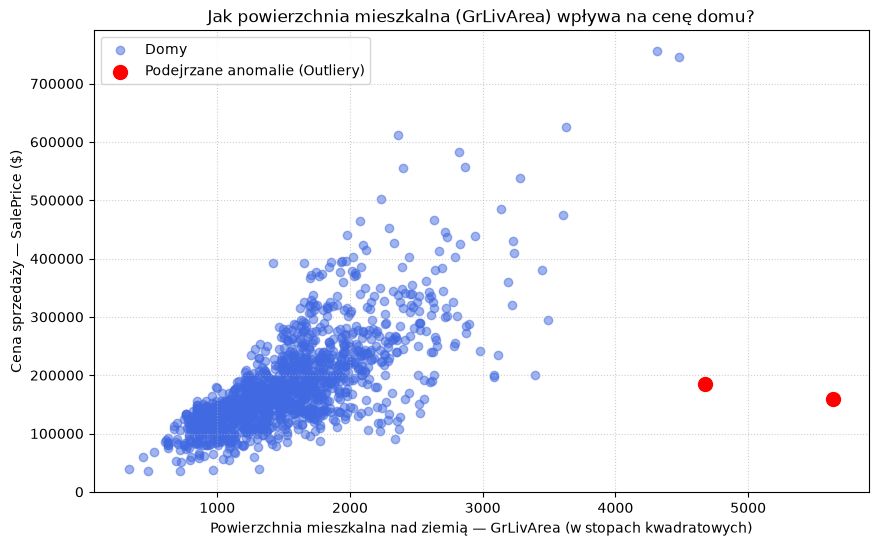

In [2]:
# WYKRES PUNKTOWY (Scatter Plot): Metraż domu (GrLivArea) a jego cena (SalePrice)
plt.figure(figsize=(10, 6))

# Rysujemy wszystkie domy jako niebieskie kropki
plt.scatter(train['GrLivArea'], train['SalePrice'], alpha=0.5, color='royalblue', label='Domy')

# Zaznaczmy na czerwono dziwne przypadki: ogromny metraż (> 4000), a niska cena (< 300 000 $)
podejrzane = train[(train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)]
plt.scatter(podejrzane['GrLivArea'], podejrzane['SalePrice'], color='red', s=100, label='Podejrzane anomalie (Outliery)')

plt.title('Jak powierzchnia mieszkalna (GrLivArea) wpływa na cenę domu?')
plt.xlabel('Powierzchnia mieszkalna nad ziemią — GrLivArea (w stopach kwadratowych)')
plt.ylabel('Cena sprzedaży — SalePrice ($)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### 🔎 Wykres punktowy (`plt.scatter`) — matematyka trendu liniowego i pułapka anomalii (*Outlierów*)

Kiedy chcesz sprawdzić, jak **jedna liczba ciągła wpływa na drugą liczbę** (np. metraż na cenę, wzrost na wagę), najlepszym narzędziem jest **wykres punktowy (`plt.scatter`)**.
* Oś pozioma (X) to `GrLivArea` (powierzchnia mieszkalna nad ziemią w stopach kwadratowych; $1\text{ m}^2 \approx 10.76\text{ stóp}^2$).
* Oś pionowa (Y) to `SalePrice` (cena domu w dolarach).
* **Każda pojedyncza kropka to jeden z 1460 domów!**

---

#### 1. Co dzieje się pod maską? (Korelacja dodatnia i linia trendu)
Spójrz na niebieską chmurę kropek: układa się ona w ukośny pas biegnący od lewego dolnego rogu w stronę prawego górnego rogu. W matematyce i statystyce nazywamy to **dodatnią zależnością liniową (korelacją dodatnią)**:
* Średnio każdy dodatkowy **1000 stóp kwadratowych** powierzchni podnosi cenę domu o około **100 000 – 120 000 \$**.
* Kiedy w kolejnych lekcjach uruchomimy model Machine Learningu (np. Regresję Liniową), jego zadaniem będzie **przeciągnięcie prostej linii przez sam środek tej chmury kropek** (tak, aby linia była jak najbliżej wszystkich punktów).

#### 2. Dlaczego dwie czerwone kropki (*Outliery*) są tak groźne dla modelu ML?
Spójrz na prawy dolny róg wykresu! Mamy tam **dwa gigantyczne domy** (wiersze o `Id = 524` oraz `Id = 1299`):
* Mają powierzchnię **`4676`** oraz **`5642` stóp kwadratowych** (to ogromne pałace po 430–520 $\text{m}^2$, oba mają najwyższą ocenę jakości `OverallQual = 10`!).
* Zostały jednak sprzedane za zaledwie **`184 750 $`** oraz **`160 000 $`** (w kolumnie `SaleCondition` mają wpisane `'Partial'` — prawdopodobnie nieukończona budowa lub transakcja rodzinna).

**Co takie dwa punkty robią z matematyką modelu?**  
Model próbuje poprowadzić linię prostą tak, żeby nie pomylić się za bardzo na żadnym domu. Te dwie czerwone kropki na samym końcu osi X działają jak **ciężki odważnik zawieszony na końcu wędki** — ciągną całą linię trendu w dół! Gdybyśmy ich nie wykryli na wykresie i nie usunęli przed treningiem, nasz model zaniżałby wycenę wszystkich dużych domów.

---

#### 3. Nowa składnia Pythona w powyższej komórce:
* **`plt.scatter(x, y, alpha=0.5, s=100)`**:
  * Pierwszy argument (`train['GrLivArea']`) to współrzędne na osi poziomej **X**.
  * Drugi argument (`train['SalePrice']`) to współrzędne na osi pionowej **Y**.
  * **`alpha=0.5`** to **przezroczystość** w skali od `0.0` (całkowicie niewidoczne) do `1.0` (pełny kolor). Przy 1460 domach kropki nachodzą na siebie — dzięki `alpha=0.5` tam, gdzie jest dużo domów, kolor robi się ciemniejszy!
  * **`s=100`** (od *size* — rozmiar) powiększa czerwone kropki anomalii, żeby od razu rzucały się w oczy.
* **`train[(train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)]`**:
  * Znak **`&`** (ampersand) oznacza w `pandas` logiczne **„ORAZ” (oba warunki muszą być spełnione jednocześnie)**.
  * **Dlaczego wokół obu warunków są nawiasy okrągłe `(...) & (...)`?** Bo w Pythonie znak `&` ma bardzo wysoki priorytet (jak mnożenie przed dodawaniem w szkolnej matematyce). Bez nawiasów okrągłych Python próbowałby najpierw połączyć `4000 & train['SalePrice']` i wyrzuciłby błąd!

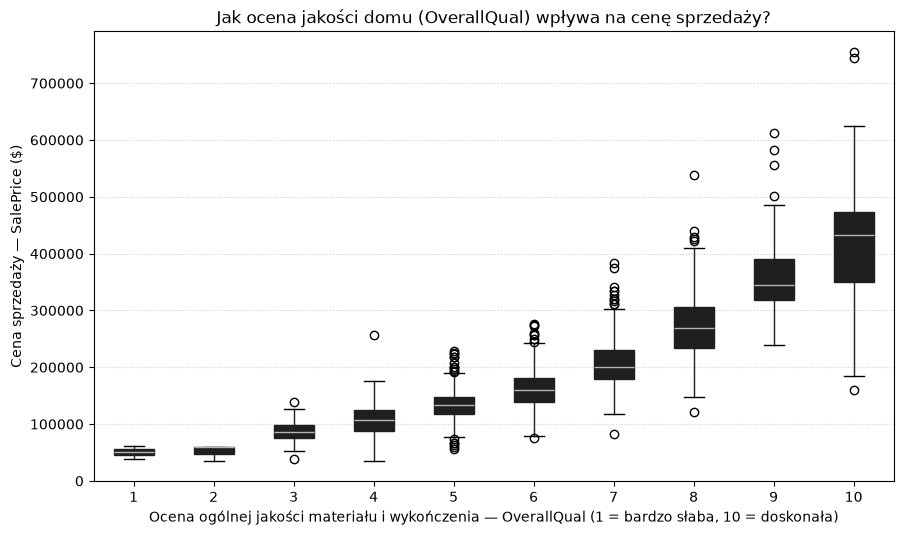

In [3]:
# WYKRES PUDEŁKOWY (Boxplot): Jakość wykonania domu (OverallQual 1-10) a jego cena (SalePrice)
fig, ax = plt.subplots(figsize=(10, 6))

# Rysujemy pudełka cen dla każdej oceny jakości (od 1 do 10)
train.boxplot(column='SalePrice', by='OverallQual', ax=ax, grid=False, patch_artist=True)

plt.title('Jak ocena jakości domu (OverallQual) wpływa na cenę sprzedaży?')
plt.suptitle('')  # Usuwamy domyślny, brzydki podtytuł automatycznie dodawany przez pandas
plt.xlabel('Ocena ogólnej jakości materiału i wykończenia — OverallQual (1 = bardzo słaba, 10 = doskonała)')
plt.ylabel('Cena sprzedaży — SalePrice ($)')
plt.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.show()

### 📦 Wykres pudełkowy (`.boxplot()`) — pełna anatomia matematyczna „pudełka z wąsami”

Kolumna `OverallQual` to nie jest ciągła liczba jak metraż, lecz **ocena w skali od 1 do 10** (gdzie `1` to rudera, `5` to przeciętny standard, a `10` to najwyższy luksus). Gdy na osi poziomej mamy takie stopnie/kategorie, używamy **wykresu pudełkowego (Boxplot)**, który w jednym rysunku zamyka całą statystykę z `.describe()` dla każdej grupy osobno!

---

#### 1. Z czego dokładnie składa się każde pudełko? (Na przykładzie pudełka dla oceny `OverallQual = 7`)

Wyobraź sobie, że bierzemy wszystkie **319 domów**, które dostały ocenę jakości **`7`**, i ustawiamy je w szeregu od najtańszego do najdroższego. Następnie dzielimy ten szereg na **4 równe ćwiartki (tzw. kwartyle — po 25% domów w każdej części)**:

| Element na wykresie pudełkowym | Nazwa w statystyce / `.describe()` | Dokładna wartość dla `OverallQual = 7` | Co to oznacza po ludzku? |
| :--- | :--- | :--- | :--- |
| **Dolna krawędź pudełka** | **1. Kwartyl ($Q_1$ / `25%`)** | **179 470 \$** | Dokładnie 25% domów o jakości 7 jest tańszych niż ta kwota, a 75% jest droższych. |
| **Kreska w środku pudełka** | **Mediana ($Q_2$ / `50%`)** | **200 141 \$** | **Środkowy dom** w grupie jakości 7. Połowa kosztuje mniej, połowa więcej. |
| **Górna krawędź pudełka** | **3. Kwartyl ($Q_3$ / `75%`)** | **230 750 \$** | 75% domów o jakości 7 kosztuje mniej niż ta kwota, a tylko 25% najdroższych ją przebija. |
| **Wysokość samego pudełka** | **Rozstęp ćwiartkowy ($\text{IQR} = Q_3 - Q_1$)** | **51 280 \$** *(230 750 - 179 470)* | W tym „pudełku” mieści się **środkowe 50% najbardziej typowych domów** o jakości 7! Im wyższe pudełko, tym większy rozstrzał cen. |
| **Górny i dolny „wąs” (linie T)** | **Granica typowych wartości ($1.5 \times \text{IQR}$)** | Góra do **~307 670 \$**, dół do **82 500 \$** | Komputer bierze wysokość pudełka ($51\,280\ \$$), mnoży ją przez **`1.5`** ($= 76\,920\ \$$) i o tyle maksymalnie pozwala wydłużyć wąsy w górę i w dół od pudełka. |
| **Kółeczka nad górnym wąsem** | **Wartości odstające (*Outliers*)** | Domy od **310 000 \$ do 383 970 \$** | Domy, które wystają poza zasięg wąsów ($> Q_3 + 1.5 \times \text{IQR}$). To wyjątkowo drogie egzemplarze jak na jakość 7 (np. mające ogromną działkę lub basen). |

---

#### 2. Matematyczny wniosek z wykresu: Zależność nieliniowa (wykładnicza)!
Spójrz, jak układają się kolejne pudełka od oceny `1` do `10`:
* Między jakością `3`, `4` a `5` mediana rośnie powoli (o około **15 000 – 25 000 \$** za każdy punkt jakości).
* Ale między jakością `7` a `8` skok wynosi już **+70 000 \$**, a między `9` a `10` aż **+120 000 \$**!
* Ponadto zobacz, że dla jakości `9` i `10` **same pudełka robią się bardzo wysokie** — oznacza to, że wśród luksusowych rezydencji rozpiętość cen jest znacznie większa niż wśród tanich domków.

In [4]:
# 🎯 ĆWICZENIE 1: Jak odwrócić logarytm? (np.log1p oraz np.expm1)
# Kiedy nasz model nauczy się przewidywać zlogarytmowaną cenę (np. wyjdzie mu liczba 12.21),
# będziemy musieli zamienić ją z powrotem na prawdziwe dolary!
# Funkcją odwrotną do `np.log1p()` jest `np.expm1()`.
#
# 1. Stwórz zmienną `cena_log` i przypisz do niej wynik funkcji np.log1p(200000)
# 2. Wypisz `cena_log` za pomocą print()
# 3. Stwórz zmienną `cena_dolary`, używając funkcji np.expm1(cena_log), i wypisz ją za pomocą print()!

# Miejsce na Twój kod:


In [5]:
# 🎯 ĆWICZENIE 2: Detektyw danych — sprawdzamy 2 podejrzane domy (Outliery)
# Na wykresie punktowym widzieliśmy dwie czerwone kropki: ogromne domy sprzedane bardzo tanio.
#
# 1. Stwórz zmienną `anomalie`, filtrując tabelę `train` dwoma warunkami naraz:
#    (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
# 2. Wyświetl z tabeli `anomalie` 5 wybranych kolumn (w podwójnych nawiasach kwadratowych [[]]):
#    'Id', 'SalePrice', 'GrLivArea', 'OverallQual', 'SaleCondition'

# Miejsce na Twój kod:


---
### 📌 Podsumowanie lekcji w 3 punktach

1. **Logarytmowanie cen (`np.log1p` i `np.expm1`):** Zamiana surowych dolarów na skalę logarytmiczną zamienia skośny wykres w symetryczny „dzwon” i sprawia, że model traktuje równe błędy procentowe (np. pomyłkę o 10%) jednakowo dla tanich domków i drogich rezydencji.
2. **Wykres punktowy (`plt.scatter`) i anomalie (*Outliery*):** Metraż `GrLivArea` ma silny dodatni wpływ na cenę, ale w danych kryją się 2 nietypowe domy (`Id = 524` i `Id = 1299` o metrażu $>4000$ stóp kw. sprzedane poniżej 200 000 \$), które zaburzają linię trendu.
3. **Wykres pudełkowy (`.boxplot()`):** Pokazuje medianę ($Q_2$), środkowe 50% danych w pudełku (od $Q_1$ do $Q_3$, czyli rozstęp $\text{IQR}$) oraz wąsy ($1.5 \times \text{IQR}$). Dzięki niemu zobaczyliśmy, że wraz ze wzrostem oceny jakości `OverallQual` cena domu rośnie coraz szybciej.